## Анализ данных о Нобелевских лауреатах

### **Контекст проекта**
В этом задании мы будем работать с датасетом о лауреатах Нобелевской премии. Ваша задача — распарсить и проанализировать эти данные, ответив на ключевые вопросы о закономерностях вручения премий, демографических характеристиках лауреатов и исторических тенденциях.

### **Этап 1: Подготовка данных**

**Задача:** На этом этапе вам надо собрать структурированный список словарей с информацией о лауреатах и призах. Приведем начало нужного нам датасета.

``` {code:python}
[{'id': '745',
  'name': 'A. Michael Spence',
  'gender': 'male',
  'birth_year': 1943,
  'country_birth': 'USA',
  'country_now': 'USA',
  'prizes_relevant': [{'prize_amount': 10000000,
    'prize_amount_adjusted': 15547541,
    'award_year': 2001,
    'category_en': 'Economic Sciences',
    'prize_status': 'received'}],
  'type_': 'person'},
 {'id': '102',
  'name': 'Aage N. Bohr',
  'gender': 'male',
  'birth_year': 1922,
  'country_birth': 'Denmark',
  'country_now': 'Denmark',
  'prizes_relevant': [{'prize_amount': 630000,
    'prize_amount_adjusted': 4304697,
    'award_year': 1975,
    'category_en': 'Physics',
    'prize_status': 'received'}],
  'type_': 'person'}]
  ```

Поскольку информация о лауреатах-людях и лауреатах-организациях структурирована по-разному, а также из-за того, что часть полей в json могут отсутстввовать, необходимо реализовать функции для процессинга словарей, которые будут достаточно обобщаемыми для обоих типов данных.

**Что нужно сделать:**

На входе информация о конкретном лауреате представляет из себя кучу вложенных друг в друга словарей. Из этой структуры нам надо получить плоский словарь вида {atribute: value}, где atribute --- это один из небольшого множества интересных нам атрибутов. При этом в исходном файле 
1. пути к атрибутам могут иметь разную длину
2. атрибуты могут отсутствовать
3. атрибуты могут нуждаться в дополнительной обработке (например, поле id в исходных словарях записано как строка.)

Поскольку наивная реализация такого обработчика оказывается довольно громоздкой, вам нужно создать файл json_dict_processing.py, в котором реализован высокоуровневый функционал для решения задачи "обработать вложенный json-словарь"

Главное требование к интерфейсу: 
по (вложенному) словарю о лауреате и конфигу (см ниже) надо получить плоский словарь вида {atribute: value}.

Достичь этого можно, например, таким набором функций

* `extract_nested_value(obj, keys)` - извлекает значение из вложенных структур данных по цепочке ключей

* `process_dictionary_with_config(dictionary, config)` - обрабатывает один словарь согласно словару-конфигу (формат конфига см ниже.)

* `process_list_of_dicts_with_config(list_of_dicts, config)` - обрабатывает список словарей, эта функция нужна чтобы обработать список призов.

* `create_processor(config, list_processor=False)` - создает готовый процессор с предзагруженной конфигурацией. В случае, если list_processor == True, внутрь процессора подается process_list_of_dicts_with_config, иначе process_dictionary_with_config.

**Замечание насчет последней функции.**

Планируемое применение этой функции примерно такое:
`laureate_processor = create_processor(PERSON_CONFIG, list_processor=False)`

То есть, create_processor возвращает функцию, которая реализует функционал process_dictionary_with_config но с уже заполненным конфигом. Это повышает читаемость кода и снижает риск перепутать конфиги из-за дублирования кода.


Помимо этого нужно создать файлы-конфиги для данных по призам, лауреатам-людям, и лауреатам-организациям.

КОНФИГ для функций process_dictionary_with_config и process_list_of_dicts_with_config имеет следующий вид
```python
  {'атрибут_который_берем_сырым': ['путь', 'к', 'данным'],  # или
  'атрибут_который_нужно_обработать': (['путь', 'к', 'данным'], функция_обработки)}
  ```
В случае, если атрибут можно взять в итоговый датасет сырым, в values() словаря-конфига будет список path_list.
Если же атрибут еще надо обработать, для него в поле config[attribute] будет tuple вида (path_list, function).

Примеры атрибутов, которые можно взять сырыми: имя, размер приза. Примеры атрибутов, которые нужно обработать: год вручения приза (в сырых данных есть только полная дата, записанная как строка)

После того, как будет создан core.py, создайте конфиги laureates_configs.py и prizes_configs.py

Постарайтесь провалидировать код с помощью assert-ов, вызываемых в ноутбуке или в .py-файлах.

пример использования: 

assert 1 == True

**Валидация**

В вашем случае assert должен взять простой словарик с одним вложенным полем и какой-нибудь конфиг-файл.
Также убедитесь, что при обработке данных собственно по лауреатам в них нет странностей (смотрите ниже) 

**Атрибуты для ПРИЗА (CONFIG_PRIZE, prizes_configs.py)**

- `prize_amount` - сумма приза → `prizeAmount`
- `prize_amount_adjusted` - скорректированная сумма приза → `prizeAmountAdjusted`
- `award_year` - год вручения приза (преобразуется в целое число) → `awardYear`
- `category_en` - категория на английском → `category.en`
- `prize_status` - статус приза → `prizeStatus`

**Атрибуты для ЧЕЛОВЕКА-ЛАУРЕАТА (CONFIG_PERSON, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - имя лауреата → `knownName.en`
- `gender` - пол → `gender`
- `birth_year` - год рождения (извлекается из даты) → `birth.date`
- `country_birth` - страна рождения → `birth.place.country.en`
- `country_now` - текущая страна → `birth.place.countryNow.en`
- `prizes_relevant` - список призов лауреата → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Атрибуты для ОРГАНИЗАЦИИ-ЛАУРЕАТА (CONFIG_ORG, laureates_configs.py)**

- `id` - уникальный идентификатор → `id`
- `name` - название организации → `orgName.en`
- `founded_year` - год основания (извлекается из даты) → `founded.date`
- `country_founded` - страна основания → `founded.place.country.en`
- `country_now` - текущая страна → `founded.place.countryNow.en`
- `prizes_relevant` - список призов организации → `nobelPrizes` (обрабатывается процессором призов, который вы задаете в конфиге для призов)

**Вспомогательные функции:**

- `process_year(year_string)` - извлекает год из строки даты (формат "YYYY-MM-DD"). Функция находится в файле laureates_configs.py
- `prize_processor()` - создает процессор для обработки списков призов. Функция находится в файле prizes_configs.py
- `person_processor()` - создает процессор для данных о людях-лауреатах. Функция находится в файле laureates_configs.py
- `org_processor()` - создает процессор для данных об организациях-лауреатах. Функция находится в файле laureates_configs.py

In [1]:
import json
from pathlib import Path

# Читаем локальный файл с исходными данными; сетевых запросов нет.
data_path = Path("laureates.json")
with data_path.open(encoding="utf-8") as file:
    laureates = json.load(file)

# Убеждаемся, что в JSON есть ожидаемый список записей.
assert "laureates" in laureates
print(
    f"Загружено записей о лауреатах: {len(laureates['laureates'])} "
    f"из файла {data_path}."
)


Загружено записей о лауреатах: 1028 из файла laureates.json.


In [2]:
from json_dict_processing import process_dictionary_with_config
from laureates_configs import CONFIG_PERSON, process_orgs, process_persons

# Проверяем извлечение вложенного имени и преобразование id по конфигу.
assert process_dictionary_with_config(
    {"id": "7", "knownName": {"en": "Ada"}}, CONFIG_PERSON
) == {
    "id": 7,
    "name": "Ada",
    "gender": None,
    "birth_year": None,
    "country_birth": None,
    "country_now": None,
    "prizes_relevant": [],
}

# Тип записи определяем по ключу, характерному для человека или организации.
def get_laureate_data(laureate):
    """Преобразует JSON-запись о лауреате и указывает тип записи."""
    if "knownName" in laureate:
        processed = process_persons([laureate])[0]
        processed["type_"] = "person"
    elif "orgName" in laureate:
        processed = process_orgs([laureate])[0]
        processed["type_"] = "org"
    else:
        raise ValueError(f"Неизвестный тип записи лауреата: {laureate.get('id')}")
    return processed


# Преобразуем все записи и разделяем их для дальнейшего анализа.
laureates_data = [get_laureate_data(item) for item in laureates["laureates"]]
people = [item for item in laureates_data if item["type_"] == "person"]
organizations = [item for item in laureates_data if item["type_"] == "org"]

# Проверяем, что каждая запись попала ровно в одну из двух групп.
assert len(people) + len(organizations) == len(laureates_data)
print(f"Лауреатов-физических лиц: {len(people)}; организаций: {len(organizations)}")
example = laureates_data[0]
print("Пример обработанной записи:")
print(
    f"Идентификатор: {example['id']}; имя: {example['name']}; "
    f"год рождения: {example['birth_year']}; "
    f"страна рождения: {example['country_birth']}."
)
for prize in example["prizes_relevant"]:
    print(
        f"Премия: {prize['category_en']}, "
        f"год вручения: {prize['award_year']}, "
        f"статус: {prize['prize_status']}."
    )


Лауреатов-физических лиц: 1000; организаций: 28
Пример обработанной записи:
Идентификатор: 745; имя: A. Michael Spence; год рождения: 1943; страна рождения: USA.
Премия: Economic Sciences, год вручения: 2001, статус: received.




### **Этап 2: EDA лауреатов**

EDA или Exploratory Data Analysis - первый шаг при работе с любыми данными.

Чтобы начать работать с этой секцией, проведите проведите чисто технический анализ собранных данных.

1. Сколько всего записей?
2. Все ли значения полей заполнены?
3. Если нет, сколько пропусков в каждом из полей? Выведите ответ на этот вопрос в формате `{'field_name': missing_values}`. А какая доля пропусков?
5. Каковы максимальные и минимальные значения поля id и каким годам награждения они соответствуют? Есть ли записи с повторяющимися id? Есть ли пары айди, которые в отсортированном массиве айдишников различаются более, чем на один? 

При реализации ответов на эти вопросы, пользуйтесь теми же принципами, что описаны выше. Можете начать с плохого хакерского кода, однако в таком случае в маркдауне пропишите, как будете его обобщать и разносить по функциям и модулям. (об этом ниже)

В основном EDA пользуйтесь аккуратным кодом, разбитым на функции и файлы.

In [3]:
from collections import Counter

# Считаем пропуски для каждого поля и их долю от общего числа записей.
records_count = len(laureates_data)
all_fields = sorted({key for record in laureates_data for key in record})
missing_counts = {
    field: sum(record.get(field) is None for record in laureates_data)
    for field in all_fields
}
missing_shares = {
    field: missing_counts[field] / records_count
    for field in all_fields
}

print(f"Всего записей о лауреатах: {records_count}")
print("Количество пропусков по полям:", missing_counts)
print("Доля пропусков по полям:")
print({key: round(value, 3) for key, value in missing_shares.items()})

# Проверяем, что идентификаторы заполнены и не повторяются.
ids = [record["id"] for record in laureates_data if record["id"] is not None]
id_counts = Counter(ids)
duplicates = sorted(
    identifier
    for identifier, count in id_counts.items()
    if count > 1
)

# Собираем годы награждения, чтобы проверить записи с крайними id.
def award_years(record):
    """Возвращает отсортированный список годов вручения премий."""
    return sorted(
        prize["award_year"]
        for prize in record["prizes_relevant"]
        if prize["award_year"] is not None
    )

minimum_id_record = min(laureates_data, key=lambda record: record["id"])
maximum_id_record = max(laureates_data, key=lambda record: record["id"])
print(
    "Минимальный идентификатор:",
    minimum_id_record["id"],
    minimum_id_record["name"],
    "годы вручения премий:",
    award_years(minimum_id_record),
)
print(
    "Максимальный идентификатор:",
    maximum_id_record["id"],
    maximum_id_record["name"],
    "годы вручения премий:",
    award_years(maximum_id_record),
)
print("Повторяющиеся идентификаторы:", duplicates)

# Находим разрывы между соседними id в отсортированном списке.
sorted_ids = sorted(ids)
id_gaps = [
    (left, right)
    for left, right in zip(sorted_ids, sorted_ids[1:])
    if right - left > 1
]
print(f"Пар идентификаторов с разрывом больше единицы: {len(id_gaps)}")
print("Первые 20 таких пар:", id_gaps[:20])

assert records_count == len(ids)
assert not duplicates
assert all(record["prizes_relevant"] for record in laureates_data)


Всего записей о лауреатах: 1028
Количество пропусков по полям: {'birth_year': 28, 'country_birth': 31, 'country_founded': 1004, 'country_now': 7, 'founded_year': 1001, 'gender': 28, 'id': 0, 'name': 0, 'prizes_relevant': 0, 'type_': 0}
Доля пропусков по полям:
{'birth_year': 0.027, 'country_birth': 0.03, 'country_founded': 0.977, 'country_now': 0.007, 'founded_year': 0.974, 'gender': 0.027, 'id': 0.0, 'name': 0.0, 'prizes_relevant': 0.0, 'type_': 0.0}
Минимальный идентификатор: 1 Wilhelm Conrad Röntgen годы вручения премий: [1901]
Максимальный идентификатор: 1070 Michael Woodford годы вручения премий: [2026]
Повторяющиеся идентификаторы: []
Пар идентификаторов с разрывом больше единицы: 24
Первые 20 таких пар: [(6, 8), (93, 95), (169, 172), (255, 257), (468, 470), (503, 505), (520, 523), (541, 543), (569, 571), (590, 592), (594, 596), (597, 600), (610, 613), (615, 617), (631, 633), (635, 637), (645, 647), (655, 657), (783, 786), (787, 789)]



Поскольку это курс по Python, а не по статистике или визуализации данных, мы не задаем жесткие рамки того, что вы должны проанализировать.
Однако это отличная возможность представить себя в роли разработчика базы данных или, например, библиотеки pandas.

В коде нужно соблюдать следующие правила:

1. должны быть реализованы  несколько способов работы с данными (среднее/медианное/максимальное значение метрики, количество примеров, вывод топ-N объектов по значению метрики).
2. анализ выбранных вами тем должен включать в себя анализ метрик в тотале, по категориям и в динамике по годам или десятилетиям.
3. проанализировать стоит 2-3 темы. Вы можете использовать темы ниже или взять свои.
2. вывод ноутбука должен быть понятен обывателю. Это может быть визуализация в matplotlib/seaborn. Сопровождайте вывод markdown-ячейками с вашими  мыслями, пояснениями и инсайтами, которые удалось извлечь.
3. Нельзя использовать pandas и numpy, но можно вдохновляться их интерфейсом и функционалом при дизайне ваших функций.


Из пункта 2 следует, что вам придется работать не только с атрибутами лауреатов, но и самих призов.
Информацию о призах нужно доставать и записывать как атрибут уже лауреата. Функции, работающие с призами (например, факт того, что лауреат отказался от какого-то из призов) можно реализовать в ноутбуке, но если вы создаете более общие вспомогательные функции, выносите их в отдельные модули.

Мы рекомендуем следующую структуру кода:

* `dataset_helpers.py` в котором реализованы фильтрация списка словарей (плоских) по условиям (аналог sql-ного where), а также аналог sql-ного групбая. А также функция для применения агрегаций к списку словарей
* `aggregations.py` в котором реализованы функции расчета среднего/медианы/других эвристик и мб вывод топ n-значений по какой-то метрике.
* `atribute_manager.py` в котором реализован переиспользуемый интерфейс для добавления (и мб удаления) полей.

Замечание насчет group-by. 

На игрушесном примере она может работать примерно так:
```
    Входные данные: [
        {'name': 'Alice', 'country': 'USA', 'age': 25},
        {'name': 'Bob', 'country': 'UK', 'age': 30},
        {'name': 'Charlie', 'country': 'USA', 'age': 25}
    ]
    
    group_by_attributes(data, ['country', 'age']) → {
        ('USA', 25): [
            {'name': 'Alice', 'country': 'USA', 'age': 25},
            {'name': 'Charlie', 'country': 'USA', 'age': 25}
        ],
        ('UK', 30): [
            {'name': 'Bob', 'country': 'UK', 'age': 30}
        ]
    }
```

Замечание насчет agregations.py
1. Агрегации соответственно должны применяться к спискам вида [
    {'name': 'Alice', 'country': 'USA', 'age': 25},
    {'name': 'Charlie', 'country': 'USA', 'age': 25}
]
2. Пользуйтесь модулем statistics из стандартной библиотеки питона.


Эта структура одна из возможных для организации вашего кода, главное, чтобы эти достаточно общие функции блыи переиспользованы

----------

При анализе данных вам понадобятся более конкретные функции, например filter_by_num_prizes или output_metric_by_category. Их пишите прямо в ноутбуке и сопровождайте коментами.

Ниже мы приводим некоторые примеры вопросов, которые может быть интересно задать к данным, но если у вас есть желание, можете поисследовать датасет с любой интересной вам стороны!


**2.1. Топ-статистика по странам**
- Определите топ-5 стран по общему количеству лауреатов
- Постройте аналогичные рейтинги отдельно по категориям (физика, химия, медицина и т.д.)

**2.2. Возраст при награждении**
- Рассчитать средний возраст лауреатов на момент получения **первого** приза. Рассмотрите только лауреатов-людей.
- Исследуйте, как средний возраст получения первого приза различается по категориям
- Различаются ли средний и медианный возрасты? 

**2.3. Гендерное распределение**
- Как менялось количество женщин-лауреатов по десятилетиям?
- Сравните распределение лауреаток по категориям. Выведите значения суммарно за все годы и по декадам.
- В какой из категорий больше всего женщин лауреаток изначально и в последние пару десятилетий?

**2.4. Миграции лауреатов**
- У скольки лауреатов исходная страна и страна на момент вручения нобелевской премии различаются? Всегда ли это различие объясняется миграцией? Добавьте вспомогательное поле 'country_of_origin_adjusted_for_migration', чтобы различие между этим полем и страной на момент вручения объяснялось миграцией.
- Выявите страны с наибольшей долей "оттекших" и "притекших" лауреатов.
- Есть ли оттоки среди организаций?

**2.5. Многократные лауреаты**
- Найдите лауреатов, получившие больше одного приза. Кто получил больше 2 раз? 
- Совпадает ли категория второго приза с первой?  
- Сколько в среднем времени прошло между получением первой и второй премии?

**2.6 Отказы от премий**
- Определите, в каких категориях чаще отказывались от премий?
- Есть ли отказы среди организаций?

---------

## Бонусное задание на +2 балла


### Лингвистический анализ мотиваций**

**5.1. Анализ текстов мотиваций**
- Соберите корпус текстов мотиваций вручения премий. Для этого измените конфиг обработки призов.
- Выделите самые частые топ-50 слов. Какие из этих слов самые частые в принципе в английском языке (такие, как for, the и другие), а какие кажутся важными именно в контексте вручения Нобелевской премии (например, 'chemistry')?
- Самые частые слова, которые также являются частыми во всем английском языке занесите в отдельный конфиг-файл под названием `stopwords.py`. Вычистите их из текстов. Какие слова являются самыми частыми теперь? Сравните множества топ-10 самых частых слов по разным категориям


- Если есть желание, посчитайте TF-IDF + сравнените топ слов по этой метрике с просто самыми популярными словами)

## 2.1. Топ-статистика по странам

Сравним топ-5 стран рождения лауреатов в целом и отдельно по категориям. Дополнительно посмотрим, как рейтинги менялись по десятилетиям.

In [4]:
from dataset_helpers import aggregate_groups, filter_records
from aggregations import (
    average,
    count,
    count_unique,
    maximum,
    median_value,
    top_n,
)

# Создаём по одной аналитической записи на каждую премию лауреата.
award_records = []
for laureate in laureates_data:
    for prize in laureate["prizes_relevant"]:
        award_records.append(
            {
                **prize,
                "laureate_id": laureate["id"],
                "name": laureate["name"],
                "type_": laureate["type_"],
                "gender": laureate.get("gender"),
                "country_birth": laureate.get("country_birth"),
                "award_decade": prize["award_year"] // 10 * 10,
            }
        )

# Для анализа стран рождения берём только людей с указанной страной.
people_awards = filter_records(award_records, {"type_": "person"})
country_awards = [
    item for item in people_awards if item["country_birth"] is not None
]


def count_laureates(rows):
    """Считает уникальных лауреатов в группе записей."""
    return count_unique(rows, "laureate_id")


# Считаем уникальных лауреатов по стране рождения и выбираем топ-5.
country_counts = aggregate_groups(
    country_awards, ["country_birth"], {"laureates": count_laureates}
)
top_countries = sorted(
    (
        {"country": key[0], **values}
        for key, values in country_counts.items()
    ),
    key=lambda row: row["laureates"],
    reverse=True,
)[:5]
print("Топ-5 стран рождения по числу уникальных лауреатов:")
for row in top_countries:
    print(f"{row['country']}: {row['laureates']}")

# В каждой категории ищем страну с наибольшим числом уникальных лауреатов.
category_country_counts = aggregate_groups(
    country_awards,
    ["category_en", "country_birth"],
    {"laureates": count_laureates},
)
print("\nТоп-5 стран рождения по числу лауреатов в каждой категории:")
for category in sorted({item["category_en"] for item in country_awards}):
    candidates = [
        {"country": key[1], **values}
        for key, values in category_country_counts.items()
        if key[0] == category
    ]
    leaders = sorted(
        candidates, key=lambda row: row["laureates"], reverse=True
    )[:5]
    print(
        f"{category}: "
        f"{[(row['country'], row['laureates']) for row in leaders]}"
    )


# Сравниваем страны рождения отдельно для каждого десятилетия.
country_decades = aggregate_groups(
    country_awards,
    ["award_decade", "country_birth"],
    {"laureates": count_laureates},
)
print("\nПять стран рождения с наибольшим числом лауреатов по десятилетиям:")
for decade in sorted({item["award_decade"] for item in country_awards}):
    decade_rows = [
        {"country": key[1], **values}
        for key, values in country_decades.items()
        if key[0] == decade
    ]
    leaders = sorted(
        decade_rows, key=lambda row: row["laureates"], reverse=True
    )[:5]
    leaders_by_country = [
        (row["country"], row["laureates"])
        for row in leaders
    ]
    print(f"{decade}-е годы: {leaders_by_country}")

Топ-5 стран рождения по числу уникальных лауреатов:
USA: 299
United Kingdom: 94
Germany: 82
France: 61
Japan: 31

Топ-5 стран рождения по числу лауреатов в каждой категории:
Chemistry: [('USA', 59), ('United Kingdom', 26), ('Germany', 24), ('France', 12), ('Japan', 9)]
Economic Sciences: [('USA', 56), ('United Kingdom', 7), ('Canada', 5), ('France', 5), ('the Netherlands', 4)]
Literature: [('France', 12), ('USA', 10), ('Sweden', 7), ('United Kingdom', 6), ('Spain', 5)]
Peace: [('USA', 19), ('France', 9), ('Germany', 6), ('Sweden', 5), ('United Kingdom', 5)]
Physics: [('USA', 71), ('United Kingdom', 25), ('Germany', 24), ('Japan', 12), ('France', 11)]
Physiology or Medicine: [('USA', 85), ('United Kingdom', 25), ('Germany', 22), ('France', 12), ('Sweden', 8)]

Пять стран рождения с наибольшим числом лауреатов по десятилетиям:
1900-е годы: [('France', 9), ('Prussia', 6), ('Switzerland', 4), ('the Netherlands', 3), ('Russian Empire', 3)]
1910-е годы: [('France', 6), ('Prussia', 4), ('Germ

Рейтинг показывает число уникальных лауреатов по стране рождения, а не число граждан или место работы. Это важно учитывать, потому что границы стран менялись, а лауреаты могли мигрировать.

В этой выборке больше всего лауреатов родились в USA (299), затем в United Kingdom (94) и Germany (82). USA лидирует в пяти из шести категорий. В Literature больше всего лауреатов, родившихся во France. Исторические названия, например Prussia, оставлены как в исходных данных и не приравниваются к современным государствам.

## 2.2. Возраст при награждении

Для каждого лауреата-человека найдём первый год вручения премии и рассчитаем возраст по году рождения. Покажем среднее и медиану в целом и по категориям.

In [5]:
# Для каждого человека используем только его первую премию.
first_award_age_rows = []
missing_age_records = 0
invalid_age_records = 0
for person in people:
    dated_prizes = sorted(
        (prize for prize in person["prizes_relevant"]
         if prize["award_year"] is not None),
        key=lambda prize: prize["award_year"],
    )
    birth_year = person["birth_year"]
    if not dated_prizes or birth_year is None:
        missing_age_records += 1
        continue
    first_prize = dated_prizes[0]
    age = first_prize["award_year"] - birth_year
    if age < 0:
        invalid_age_records += 1
        continue
    first_award_age_rows.append(
        {"name": person["name"], "age": age,
         "category_en": first_prize["category_en"],
         "award_year": first_prize["award_year"]}
    )

print("Возраст на момент получения первой премии, только лауреаты-люди:")
print(f"Записей для расчёта: {len(first_award_age_rows)}")
print(f"Пропущено из-за отсутствующих данных: {missing_age_records}")
print(f"Исключено из-за некорректного возраста: {invalid_age_records}")
print(
    f"В целом: средний возраст {average(first_award_age_rows, 'age'):.1f}, "
    f"медианный возраст {median_value(first_award_age_rows, 'age')} лет."
)
print("Средний и медианный возраст по категории первой премии:")
for category in sorted({row["category_en"] for row in first_award_age_rows}):
    category_rows = [row for row in first_award_age_rows
                     if row["category_en"] == category]
    print(
        f"{category}: средний {average(category_rows, 'age'):.1f}, "
        f"медианный {median_value(category_rows, 'age')} лет "
        f"(лауреатов: {len(category_rows)})."
    )

Возраст на момент получения первой премии, только лауреаты-люди:
Записей для расчёта: 1000
Пропущено из-за отсутствующих данных: 0
Исключено из-за некорректного возраста: 0
В целом: средний возраст 60.6, медианный возраст 61.0 лет.
Средний и медианный возраст по категории первой премии:
Chemistry: средний 59.4, медианный 58 лет (лауреатов: 199).
Economic Sciences: средний 67.2, медианный 67 лет (лауреатов: 101).
Literature: средний 65.0, медианный 67 лет (лауреатов: 123).
Peace: средний 61.0, медианный 62.0 лет (лауреатов: 112).
Physics: средний 57.8, медианный 56.0 лет (лауреатов: 230).
Physiology or Medicine: средний 59.0, медианный 58 лет (лауреатов: 235).


## 2.3. Гендерное распределение

Организации исключены из этой части: для них пол не применим. В общем числе, по категориям и десятилетиям каждый лауреат учитывается один раз в каждой соответствующей группе.

In [6]:
# В гендерный анализ включаем только людей с известным значением пола.
known_gender_people = [
    person for person in people if person["gender"] in {"female", "male"}
]
women_people = [
    person for person in known_gender_people if person["gender"] == "female"
]
overall_women_share = len(women_people) / len(known_gender_people)
print(
    f"Женщины: {len(women_people)} из {len(known_gender_people)} лауреатов "
    f"({overall_women_share:.1%})."
)

# Долю женщин считаем среди уникальных лауреатов, а не числа премий.
known_gender_awards = [
    item for item in people_awards if item["gender"] in {"female", "male"}
]
# Сравниваем число женщин и мужчин внутри каждой категории.
gender_by_category = aggregate_groups(
    known_gender_awards,
    ["category_en", "gender"],
    {"laureates": count_laureates},
)
print("\nДоля женщин среди уникальных лауреатов в каждой категории:")
women_share_by_category = {}
for category in sorted({item["category_en"] for item in known_gender_awards}):
    female = gender_by_category.get((category, "female"), {}).get(
        "laureates", 0
    )
    male = gender_by_category.get((category, "male"), {}).get("laureates", 0)
    share = female / (female + male)
    women_share_by_category[category] = share
    print(
        f"{category}: "
        f"{female}/{female + male} ({share:.1%})"
    )

women_count_by_category = {
    category: gender_by_category.get((category, "female"), {}).get(
        "laureates", 0
    )
    for category in sorted({item["category_en"] for item in known_gender_awards})
}
print("\nЧисло женщин-лауреатов по категориям за все годы:")
for category, laureate_count in women_count_by_category.items():
    print(f"{category}: {laureate_count}")

# Затем считаем число и долю женщин по десятилетиям.
gender_by_decade = aggregate_groups(
    known_gender_awards,
    ["award_decade", "gender"],
    {"laureates": count_laureates},
)
women_count_by_decade = {}
women_share_by_decade = {}
for decade in sorted({item["award_decade"] for item in known_gender_awards}):
    female = gender_by_decade.get((decade, "female"), {}).get(
        "laureates", 0
    )
    male = gender_by_decade.get((decade, "male"), {}).get("laureates", 0)
    women_count_by_decade[decade] = female
    women_share_by_decade[decade] = female / (female + male)

print("\nЧисло и доля женщин-лауреатов по десятилетиям:")
for decade, share in women_share_by_decade.items():
    print(f"{decade}-е годы: {women_count_by_decade[decade]} ({share:.1%})")

# Для детализации оставляем только записи о женщинах-лауреатах.
women_awards = [
    item for item in known_gender_awards if item["gender"] == "female"
]
women_by_category_decade = aggregate_groups(
    women_awards,
    ["award_decade", "category_en"],
    {"laureates": count_laureates},
)
print("\nЧисло женщин-лауреатов по категориям и десятилетиям:")
for decade in sorted({item["award_decade"] for item in known_gender_awards}):
    category_counts = {
        category: women_by_category_decade.get(
            (decade, category), {}
        ).get("laureates", 0)
        for category in sorted({item["category_en"] for item in women_awards})
    }
    print(f"{decade}-е годы: {category_counts}")

# Сравниваем первую и две последние декады, представленные в данных.
first_decade = min(women_count_by_decade)
recent_decades = sorted(women_count_by_decade)[-2:]
first_category_counts = {
    category: women_by_category_decade.get(
        (first_decade, category), {}
    ).get("laureates", 0)
    for category in sorted({item["category_en"] for item in women_awards})
}
recent_category_counts = {
    category: sum(
        women_by_category_decade.get((decade, category), {}).get(
            "laureates", 0
        )
        for decade in recent_decades
    )
    for category in sorted({item["category_en"] for item in women_awards})
}
first_max = max(first_category_counts.values())
recent_max = max(recent_category_counts.values())
first_leaders = sorted(
    category
    for category, laureate_count in first_category_counts.items()
    if laureate_count == first_max
)
recent_leaders = sorted(
    category
    for category, laureate_count in recent_category_counts.items()
    if laureate_count == recent_max
)
print(
    f"\nБольше всего женщин в {first_decade}-е годы: "
    f"{', '.join(first_leaders)} "
    f"({first_max})."
)
print(
    f"Больше всего женщин с {recent_decades[0]}-х по {recent_decades[-1]}-е годы: "
    f"{', '.join(recent_leaders)} "
    f"({recent_max})."
)

Женщины: 69 из 1000 лауреатов (6.9%).

Доля женщин среди уникальных лауреатов в каждой категории:
Chemistry: 8/200 (4.0%)
Economic Sciences: 3/101 (3.0%)
Literature: 19/123 (15.4%)
Peace: 21/113 (18.6%)
Physics: 5/230 (2.2%)
Physiology or Medicine: 14/235 (6.0%)

Число женщин-лауреатов по категориям за все годы:
Chemistry: 8
Economic Sciences: 3
Literature: 19
Peace: 21
Physics: 5
Physiology or Medicine: 14

Число и доля женщин-лауреатов по десятилетиям:
1900-е годы: 3 (5.4%)
1910-е годы: 1 (2.6%)
1920-е годы: 2 (3.7%)
1930-е годы: 3 (5.5%)
1940-е годы: 3 (7.5%)
1950-е годы: 0 (0.0%)
1960-е годы: 3 (4.0%)
1970-е годы: 4 (3.9%)
1980-е годы: 4 (4.3%)
1990-е годы: 7 (6.9%)
2000-е годы: 11 (9.2%)
2010-е годы: 13 (11.1%)
2020-е годы: 16 (19.5%)

Число женщин-лауреатов по категориям и десятилетиям:
1900-е годы: {'Chemistry': 0, 'Economic Sciences': 0, 'Literature': 1, 'Peace': 1, 'Physics': 1, 'Physiology or Medicine': 0}
1910-е годы: {'Chemistry': 1, 'Economic Sciences': 0, 'Literature': 0,

В выборке 69 из 1 000 лауреатов-людей с известным полом являются женщинами (6,9%). Самая высокая доля среди категорий у Peace (18,6%), затем у Literature (15,4%). В 1900-е в Literature, Peace и Physics была по одной лауреатке. С 2010-х по 2020-е больше всего женщин в категории Peace (9). В 2020-е доля женщин составляет 19,5%; десятилетие ещё не завершено.

## 2.4. Миграции лауреатов

В исходном JSON нет сведений о месте жительства лауреата в год вручения. Поэтому для приближённого сравнения используем страну первой аффилиации в данных о премии. Вспомогательное поле `country_of_origin_adjusted_for_migration` приводит страну рождения к современному названию страны в этом месте; различие с аффилиацией может указывать на переезд, но не доказывает его. Для организаций отдельно проверим, есть ли данные, позволяющие оценить перемещение.

In [7]:
from collections import Counter

# Нормализуем страну места рождения/основания по современным границам.
raw_by_id = {int(row["id"]): row for row in laureates["laureates"]}
for laureate in laureates_data:
    raw_record = raw_by_id[laureate["id"]]
    location_key = "birth" if laureate["type_"] == "person" else "founded"
    place = ((raw_record.get(location_key) or {}).get("place") or {})
    historical_country = (place.get("country") or {}).get("en")
    modern_country = (place.get("countryNow") or {}).get("en")
    origin_country = modern_country or historical_country
    # Scotland и Northern Ireland сопоставляем с United Kingdom для сравнения.
    country_aliases = {
        "Scotland": "United Kingdom",
        "Northern Ireland": "United Kingdom",
    }
    laureate["country_of_origin_adjusted_for_migration"] = country_aliases.get(
        origin_country, origin_country
    )

# Отличия названий страны рождения показывают изменение границ, а не переезд.
birth_country_label_differences = 0
people_with_both_birth_country_labels = 0
for person in people:
    raw_record = raw_by_id[person["id"]]
    place = ((raw_record.get("birth") or {}).get("place") or {})
    historical_country = (place.get("country") or {}).get("en")
    modern_country = (place.get("countryNow") or {}).get("en")
    if historical_country and modern_country:
        people_with_both_birth_country_labels += 1
        if historical_country != modern_country:
            birth_country_label_differences += 1

# Сравниваем страну происхождения с первой аффилиацией первой премии.
flow_rows = []
for person in people:
    raw_record = raw_by_id[person["id"]]
    raw_prizes = sorted(
        raw_record.get("nobelPrizes", []),
        key=lambda prize: int(prize.get("awardYear") or 999999),
    )
    if not raw_prizes:
        continue
    affiliations = raw_prizes[0].get("affiliations") or []
    if not affiliations:
        continue
    affiliation = affiliations[0]
    award_country = (
        (affiliation.get("countryNow") or {}).get("en")
        or (affiliation.get("country") or {}).get("en")
    )
    origin_country = person["country_of_origin_adjusted_for_migration"]
    if origin_country and award_country:
        flow_rows.append(
            {"id": person["id"], "name": person["name"],
             "origin": origin_country, "award_country": award_country}
        )

country_differences = [
    row for row in flow_rows if row["origin"] != row["award_country"]
]
print(
    "Название страны рождения отличается от современного названия места "
    f"рождения у {birth_country_label_differences} из "
    f"{people_with_both_birth_country_labels} лауреатов; это различие "
    "границ, а не свидетельство миграции."
)
print(
    "Страна происхождения после поправки отличается от страны первой "
    f"аффилиации у {len(country_differences)} из {len(flow_rows)} "
    "лауреатов с доступными данными. Аффилиация является приближённым "
    "показателем страны, связанной с премией."
)

# Доли считаются среди лауреатов с известными странами происхождения и аффилиации.
outflow_base = Counter(row["origin"] for row in flow_rows)
inflow_base = Counter(row["award_country"] for row in flow_rows)
outflow_counts = Counter(row["origin"] for row in country_differences)
inflow_counts = Counter(row["award_country"] for row in country_differences)

def print_flow_rates(title, moved_counts, base_counts):
    print(title)
    ranked = sorted(
        moved_counts,
        key=lambda country: (
            moved_counts[country] / base_counts[country],
            moved_counts[country],
            country,
        ),
        reverse=True,
    )[:5]
    for country in ranked:
        moved = moved_counts[country]
        total = base_counts[country]
        print(f"{country}: {moved}/{total} ({moved / total:.1%})")

print_flow_rates("Пять наибольших долей оттока по стране происхождения:", outflow_counts, outflow_base)
print_flow_rates("Пять наибольших долей притока по стране аффилиации:", inflow_counts, inflow_base)

# У организаций проверяем доступность аффилиаций и различия границ.
organization_rows = [row for row in laureates_data if row["type_"] == "org"]
organizations_with_affiliations = 0
organization_country_label_differences = 0
organizations_with_both_country_labels = 0
for organization in organization_rows:
    raw_record = raw_by_id[organization["id"]]
    if any(prize.get("affiliations") for prize in raw_record.get("nobelPrizes", [])):
        organizations_with_affiliations += 1
    place = (((raw_record.get("founded") or {}).get("place")) or {})
    historical_country = (place.get("country") or {}).get("en")
    modern_country = (place.get("countryNow") or {}).get("en")
    if historical_country and modern_country:
        organizations_with_both_country_labels += 1
        if historical_country != modern_country:
            organization_country_label_differences += 1
print(
    f"Организации с данными об аффилиации: {organizations_with_affiliations} "
    f"из {len(organization_rows)}. По этим данным нельзя установить их "
    "отток/приток."
)
print(
    "Различия исторического и современного названия страны места основания "
    f"организаций: {organization_country_label_differences} из "
    f"{organizations_with_both_country_labels}; это не показатель переезда."
)

Название страны рождения отличается от современного названия места рождения у 113 из 997 лауреатов; это различие границ, а не свидетельство миграции.
Страна происхождения после поправки отличается от страны первой аффилиации у 236 из 756 лауреатов с доступными данными. Аффилиация является приближённым показателем страны, связанной с премией.
Пять наибольших долей оттока по стране происхождения:
Poland: 18/18 (100.0%)
South Africa: 4/4 (100.0%)
Ukraine: 3/3 (100.0%)
New Zealand: 3/3 (100.0%)
Turkey: 2/2 (100.0%)
Пять наибольших долей притока по стране аффилиации:
Tunisia: 1/1 (100.0%)
Canada: 6/10 (60.0%)
Switzerland: 12/24 (50.0%)
Argentina: 1/2 (50.0%)
Israel: 2/5 (40.0%)
Организации с данными об аффилиации: 0 из 28. По этим данным нельзя установить их отток/приток.
Различия исторического и современного названия страны места основания организаций: 0 из 24; это не показатель переезда.


## 2.5. Многократные лауреаты

Найдём людей и организации, получивших более одной премии, проверим, совпадают ли категории первых двух премий, и рассчитаем средний интервал между ними.

In [8]:
# Сортируем премии каждого лауреата, включая организации, по году вручения.
multiple_award_winners = []
for laureate in laureates_data:
    dated_prizes = sorted(
        (prize for prize in laureate["prizes_relevant"]
         if prize["award_year"] is not None),
        key=lambda prize: prize["award_year"],
    )
    if len(dated_prizes) > 1:
        multiple_award_winners.append(
            {
                "name": laureate["name"],
                "type_": laureate["type_"],
                "prizes": dated_prizes,
                "award_count": len(dated_prizes),
                "interval_years": (
                    dated_prizes[1]["award_year"] - dated_prizes[0]["award_year"]
                ),
            }
        )

more_than_two_awards = [
    winner for winner in multiple_award_winners if winner["award_count"] > 2
]
print(f"Лауреатов с более чем одной премией: {len(multiple_award_winners)}")
if more_than_two_awards:
    print("Получили больше двух премий:")
    for winner in more_than_two_awards:
        winner_type = "организация" if winner["type_"] == "org" else "человек"
        print(f"{winner['name']} ({winner_type}): {winner['award_count']}")
else:
    print("Лауреатов, получивших больше двух премий, в данных нет.")

same_category_count = 0
for winner in multiple_award_winners:
    first_prize, second_prize = winner["prizes"][:2]
    same_category = first_prize["category_en"] == second_prize["category_en"]
    same_category_count += same_category
    winner_type = "организация" if winner["type_"] == "org" else "человек"
    print(
        f"{winner['name']} ({winner_type}): {first_prize['award_year']} "
        f"({first_prize['category_en']}), {second_prize['award_year']} "
        f"({second_prize['category_en']}); категории "
        f"{'совпадают' if same_category else 'различаются'}, "
        f"интервал {winner['interval_years']} лет."
    )
if multiple_award_winners:
    print(
        "Средний интервал между первой и второй премиями: "
        f"{average(multiple_award_winners, 'interval_years'):.1f} лет."
    )
    print(
        f"Категории совпали у {same_category_count} из "
        f"{len(multiple_award_winners)} лауреатов."
    )

Лауреатов с более чем одной премией: 7
Получили больше двух премий:
International Committee of the Red Cross (организация): 3
Frederick Sanger (человек): 1958 (Chemistry), 1980 (Chemistry); категории совпадают, интервал 22 лет.
International Committee of the Red Cross (организация): 1917 (Peace), 1944 (Peace); категории совпадают, интервал 27 лет.
John Bardeen (человек): 1956 (Physics), 1972 (Physics); категории совпадают, интервал 16 лет.
K. Barry Sharpless (человек): 2001 (Chemistry), 2022 (Chemistry); категории совпадают, интервал 21 лет.
Linus Pauling (человек): 1954 (Chemistry), 1962 (Peace); категории различаются, интервал 8 лет.
Marie Curie (человек): 1903 (Physics), 1911 (Chemistry); категории различаются, интервал 8 лет.
Office of the United Nations High Commissioner for Refugees (организация): 1954 (Peace), 1981 (Peace); категории совпадают, интервал 27 лет.
Средний интервал между первой и второй премиями: 18.4 лет.
Категории совпали у 5 из 7 лауреатов.


## 2.6. Отказы от премий

Считаем отказами записи со статусом `declined`. Покажем количество и долю отказов по категориям, а также проверим записи об организациях.

In [9]:
from collections import Counter

# Статус отказа сверяем с исходным значением JSON.
declined_awards = [
    row for row in award_records if row["prize_status"] == "declined"
]
all_awards_by_category = Counter(row["category_en"] for row in award_records)
declined_by_category = Counter(row["category_en"] for row in declined_awards)
print(f"Всего премий со статусом declined: {len(declined_awards)}")
print("Категории с отказами (отказы / все премии категории):")
for category in sorted(declined_by_category):
    declined_count = declined_by_category[category]
    total_count = all_awards_by_category[category]
    print(
        f"{category}: {declined_count}/{total_count} "
        f"({declined_count / total_count:.2%})"
    )
print("Отказавшиеся лауреаты:")
for row in declined_awards:
    print(f"{row['name']}: {row['category_en']}, {row['award_year']} год.")

organization_refusals = [
    row for row in declined_awards if row["type_"] == "org"
]
if organization_refusals:
    print(f"Отказы среди организаций: {len(organization_refusals)}.")
else:
    print("Отказов среди организаций в данных нет.")

Всего премий со статусом declined: 2
Категории с отказами (отказы / все премии категории):
Literature: 1/123 (0.81%)
Peace: 1/144 (0.69%)
Отказавшиеся лауреаты:
Jean-Paul Sartre: Literature, 1964 год.
Le Duc Tho : Peace, 1973 год.
Отказов среди организаций в данных нет.


## Дополнительный анализ. Размер премии

Для сравнения разных лет используем скорректированную сумму. Считаем среднее, медиану и максимум в целом, по категориям и по десятилетиям. Сумма премии относится к записи о награждении, а не делится между со-лауреатами.

In [10]:
# Исключаем записи без скорректированной суммы премии.
amount_awards = [
    item
    for item in award_records
    if item["prize_amount_adjusted"] is not None
]

# Собираем основные статистики скорректированных сумм в одном месте.
def amount_summary(rows):
    """Возвращает сводные показатели скорректированных сумм премий."""
    return {
        "awards": count(rows),
        "mean_adjusted": round(average(rows, "prize_amount_adjusted"), 2),
        "median_adjusted": median_value(rows, "prize_amount_adjusted"),
        "max_adjusted": maximum(rows, "prize_amount_adjusted"),
    }

summary_labels_ru = {
    "awards": "число премий",
    "mean_adjusted": "средняя скорректированная сумма",
    "median_adjusted": "медианная скорректированная сумма",
    "max_adjusted": "максимальная скорректированная сумма",
}
print(
    "Все премии:",
    {summary_labels_ru[key]: value for key, value in amount_summary(amount_awards).items()},
)
# Сравниваем число и суммы премий между категориями.
print("\nСкорректированные суммы по категориям:")
amount_by_category = aggregate_groups(
    amount_awards,
    ["category_en"],
    {
        "awards": count,
        "mean_adjusted": lambda rows: round(
            average(rows, "prize_amount_adjusted"), 2
        ),
        "median_adjusted": lambda rows: median_value(
            rows, "prize_amount_adjusted"
        ),
        "max_adjusted": lambda rows: maximum(rows, "prize_amount_adjusted"),
    },
)
for category, summary in sorted(amount_by_category.items()):
    print(
        category[0],
        {summary_labels_ru[key]: value for key, value in summary.items()},
    )

amount_by_decade = aggregate_groups(
    amount_awards,
    ["award_decade"],
    {
        "awards": count,
        "mean_adjusted": lambda rows: round(
            average(rows, "prize_amount_adjusted"), 2
        ),
        "median_adjusted": lambda rows: median_value(
            rows, "prize_amount_adjusted"
        ),
        "max_adjusted": lambda rows: maximum(rows, "prize_amount_adjusted"),
    },
)
# Медиана помогает сравнивать типичную сумму разных десятилетий.
print("\nМедианная скорректированная сумма по десятилетиям:")
for decade, summary in sorted(amount_by_decade.items()):
    print(
        f"{decade[0]}-е годы: медиана={summary['median_adjusted']:,}; "
        f"число премий={summary['awards']}"
    )

# Показываем пять записей с наибольшей скорректированной суммой.
highest_adjusted_awards = top_n(amount_awards, "prize_amount_adjusted", n=5)
print("\nПять наибольших скорректированных сумм премий:")
for item in highest_adjusted_awards:
    print(
        f"Лауреат: {item['name']}; год: {item['award_year']}; "
        f"категория: {item['category_en']}; "
        f"скорректированная сумма: {item['prize_amount_adjusted']:,}"
    )


Все премии: {'число премий': 1036, 'средняя скорректированная сумма': 8081349.33, 'медианная скорректированная сумма': 7862394.0, 'максимальная скорректированная сумма': 15547541}

Скорректированные суммы по категориям:
Chemistry {'число премий': 202, 'средняя скорректированная сумма': 8226668.75, 'медианная скорректированная сумма': 8540220.0, 'максимальная скорректированная сумма': 15547541}
Economic Sciences {'число премий': 101, 'средняя скорректированная сумма': 10175695.47, 'медианная скорректированная сумма': 11178104, 'максимальная скорректированная сумма': 15547541}
Literature {'число премий': 123, 'средняя скорректированная сумма': 7331550.03, 'медианная скорректированная сумма': 5963742, 'максимальная скорректированная сумма': 15547541}
Peace {'число премий': 144, 'средняя скорректированная сумма': 8052882.56, 'медианная скорректированная сумма': 8617247.5, 'максимальная скорректированная сумма': 15547541}
Physics {'число премий': 231, 'средняя скорректированная сумма': 7994

Самая высокая медианная скорректированная сумма среди категорий у Economic Sciences (11 178 104), самая низкая у Physiology or Medicine (5 963 742). По десятилетиям наибольшая медиана приходится на 2000-е (14 809 494). Это суммы премий, а не доли каждого лауреата, получившего премию совместно с другими.


## Визуализация основных результатов

Графики дополняют таблицы: число награждений по категориям, изменение доли женщин и страны рождения с наибольшим числом лауреатов.


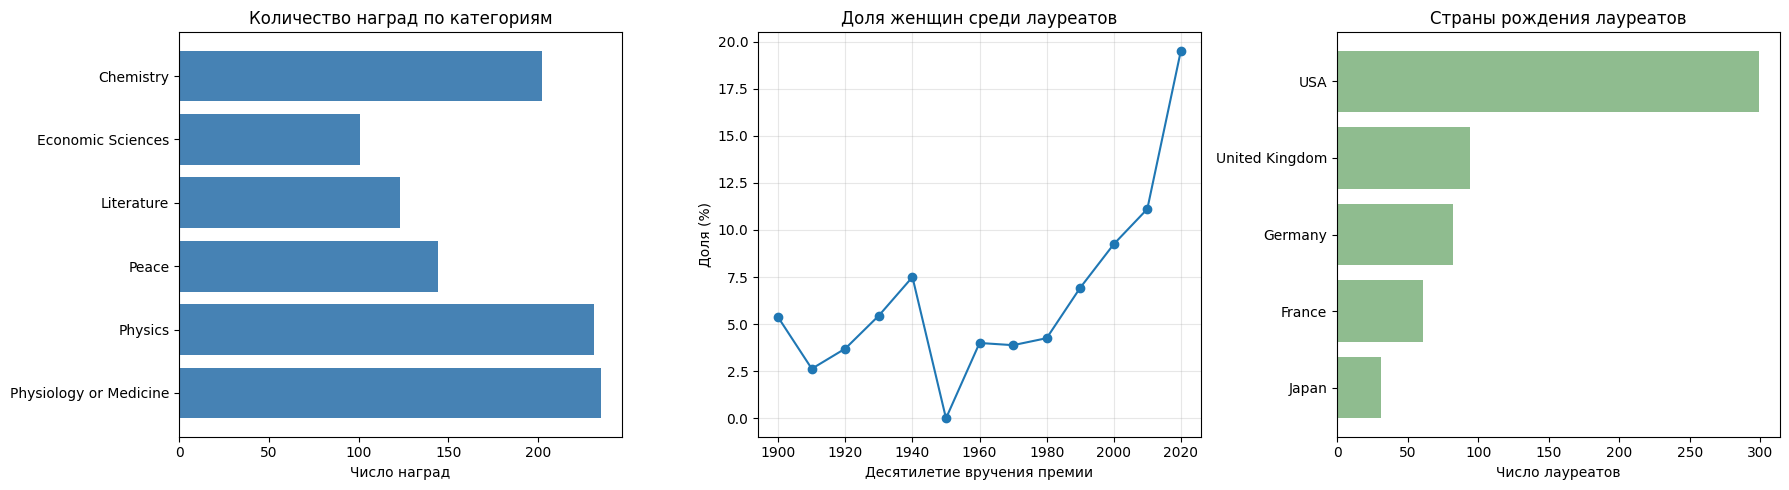

In [11]:
import matplotlib.pyplot as plt

# Построим три графика для основных результатов: категории, доля женщин и страны.
category_totals = aggregate_groups(
    award_records, ["category_en"], {"awards": count}
)
category_names = [key[0] for key in sorted(category_totals)]
category_values = [
    category_totals[(name,)]["awards"] for name in category_names
]

figure, axes = plt.subplots(1, 3, figsize=(18, 5))
# Первый график показывает количество наград по категориям.
axes[0].barh(category_names, category_values, color="steelblue")
axes[0].set_title("Количество наград по категориям")
axes[0].set_xlabel("Число наград")
axes[0].invert_yaxis()

# Второй график показывает изменение доли женщин по десятилетиям.
decades = list(women_share_by_decade)
women_percentages = [women_share_by_decade[decade] * 100 for decade in decades]
axes[1].plot(decades, women_percentages, marker="o")
axes[1].set_title("Доля женщин среди лауреатов")
axes[1].set_xlabel("Десятилетие вручения премии")
axes[1].set_ylabel("Доля (%)")
axes[1].grid(alpha=0.3)

# Третий график показывает страны рождения с наибольшим числом лауреатов.
country_labels = [row["country"] for row in top_countries[:8]]
country_values = [row["laureates"] for row in top_countries[:8]]
axes[2].barh(country_labels, country_values, color="darkseagreen")
axes[2].set_title("Страны рождения лауреатов")
axes[2].set_xlabel("Число лауреатов")
axes[2].invert_yaxis()

figure.tight_layout()
plt.show()